# Leave-one-cell-type-out: `cellina` vs a labels baseline (OOD + ID)

This notebook is an **extension of the [`cellina` tutorial](../../cellina/docs/tutorial.ipynb)**.
It runs the same leave-one-out (LOO) experiment — hold out **Myeloid** cells in the
cancer (`CRC`) region of sample **`crc_232`**, never showing them during training — then asks
each model to predict expression for control (`REF`) cells placed counterfactually into the
`CRC` microenvironment. We score `cellina` and a simple **labels baseline** with the same
metrics (`scripts/metrics.py::compare_adatas`).

Crucially, we run the `REF → CRC` counterfactual over **all cell types in one pass** (same
trained models), then split the scoring into two regimes:

- **OOD** — the held-out cell type (**Myeloid**): `(Myeloid, CRC)` was *never* seen in
  training, so this measures extrapolation to an unseen combination.
- **ID** — the held-in cell types (everything else): their `(cell type, CRC)` cells *were*
  in training, so this measures fitting a seen combination.

The **labels baseline** (`wsi.LabelsBaseline`) ignores expression and spatial context: it
predicts expression purely from the (cell-type, domain) labels — one-hot encoded and decoded
through an scvi `DecoderSCVI` with an NB likelihood and observed library size. It is the
no-context floor that a spatial model like `cellina` should beat (especially OOD).

All the LOO plumbing (preprocessing, splits, the metrics glue) is imported from
`../scripts` — the notebook only orchestrates.

## Sections

| Section | Produces |
|---|---|
| **A. Shared setup + cellina** | `observed.h5ad`, `cellina_pred.h5ad` |
| **B. Labels baseline** | `labels_pred.h5ad` |
| **C. Compare (OOD + ID)** | metric tables + plot |

Unlike the old CPA comparison (which needed a separate, incompatible `scvi-tools` env), the
labels baseline is a plain `scvi-tools` model built on the same stack as `cellina` — so the
whole notebook runs in **one kernel**: just run A, then B, then C top to bottom.

In [1]:
import os
import sys

import numpy as np
import scanpy as sc

sys.path.append(os.path.abspath("../scripts"))

from utils import set_seed
from eval import (
    preprocess_crc,
    preprocess_spatial_features,
    split_indices,
    make_comparison_adata,
    run_loo_eval,
    COUNTS_PER_K,
)

set_seed(0)

# --- experiment config -----------------------------------------------------
DATA_ROOT = os.environ.get("DATA_ROOT", ".")
ADATA_PATH = os.path.join(DATA_ROOT, "datasets/crc/crc_232.h5ad")
ZENODO_URL = "https://zenodo.org/records/15574384/files/232.h5ad?download=1"

HOLDOUT_CT = "Myeloid"
LABELS_KEY = "coarse_type"
DOMAINS_KEY = "typ_clean"
CONTROL_LABEL = "REF"   # healthy reference region
HOLDOUT_LABEL = "CRC"   # cancer region (held out for Myeloid)

PRED_DIR = "preds"      # small cache for the cross-env prediction handoff
os.makedirs(PRED_DIR, exist_ok=True)

## A. Shared setup + cellina  *(run in the `cellina` env)*

In [2]:
# Load + CRC preprocessing (coarse labels, REF/TVA/CRC domains, spatial coords, HVGs).
adata = sc.read(ADATA_PATH, backup_url=ZENODO_URL)
adata = preprocess_crc(adata, n_top_genes=2000)
adata

/data/ddimitrov/repos/wsi_cellina/scripts/eval.py:66: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[labels_key] = adata.obs[labels_key].astype("category")


AnnData object with n_obs × n_vars = 111989 × 2000
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD68_CK8_18', 'Max.CD68_CK8_18', 'Mean.CD298_B2M', 'Max.CD298_B2M', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'Dash', 'ISH.concentration', 'Panel', 'Run_Tissue_name', 'Run_name', 'assay_type', 'dualfiles', 'tissue', 'version', 'slide_ID', 'CenterX_global_px', 'CenterY_global_px', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsecode', 'falsecode_quantile_0.75', 'falsecode_quantile_0.8', 'falsecode_quantile

In [3]:
# Leave-one-cell-type-out split: test = Myeloid cells in the CRC region.
train_idx, val_idx, test_idx = split_indices(
    adata, HOLDOUT_CT, labels_key=LABELS_KEY, domains_key=DOMAINS_KEY,
    holdout_domains=[HOLDOUT_LABEL], seed=0,
)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=96259  val=10695  test=5035


In [4]:
# Spatial neighbour graph + aggregated features (held-out cells masked to avoid leakage).
adata = preprocess_spatial_features(adata, n_neighbors=200, test_indices=test_idx)

In [5]:
# Control = ALL REF cells; observed target = ALL CRC cells. We run the REF -> CRC
# counterfactual over every cell type in one pass, then split scoring (section C) into:
#   - OOD: the held-out cell type (Myeloid)  -> (Myeloid, CRC) was never seen in training
#   - ID : the held-in cell types            -> (cell type, CRC) was seen in training
is_holdout_ct = adata.obs[LABELS_KEY].astype(str) == HOLDOUT_CT
mask_control = adata.obs[DOMAINS_KEY].astype(str) == CONTROL_LABEL   # all REF cells
mask_target  = adata.obs[DOMAINS_KEY].astype(str) == HOLDOUT_LABEL   # all CRC cells (observed)
idx_control = np.where(mask_control.values)[0]
idx_target  = np.where(mask_target.values)[0]

# Cell-type labels per arm, so we can slice OOD vs ID after scoring. The counterfactual
# moves REF cells into CRC but keeps each cell's own type, so its predicted arm carries the
# REF cells' types.
ct_control = adata.obs[LABELS_KEY].astype(str).values[mask_control.values]
ct_target  = adata.obs[LABELS_KEY].astype(str).values[mask_target.values]

# Donor pool for the CRC microenvironment: observed neighbours of the CRC cells, excluding
# the held-out cell type (Myeloid) so the held-out cells never leak in as donors.
conn = adata.obsp["spatial_connectivities_orig"]
neighbor_indices = np.unique(conn[idx_target].nonzero()[1])
neighbor_indices = neighbor_indices[~is_holdout_ct.values[neighbor_indices]]
print(f"control(REF)={idx_control.size}  target(CRC)={idx_target.size}  "
      f"donor-neighbours={neighbor_indices.size}  OOD-celltype={HOLDOUT_CT!r}")

control(REF)=29731  target(CRC)=82258  donor-neighbours=80515  OOD-celltype='Myeloid'


In [6]:
# Observed pair (ground truth): real REF vs real CRC counts across all cell types, with the
# cell-type label attached so section C can slice OOD (held-out type) from ID (held-in types).
observed = make_comparison_adata(
    adata.layers["counts"][mask_control.values, :],
    adata.layers["counts"][mask_target.values, :],
    adata.var_names, control_label=CONTROL_LABEL, perturbed_label=HOLDOUT_LABEL,
)
observed.obs[LABELS_KEY] = np.concatenate([ct_control, ct_target])
observed.write(os.path.join(PRED_DIR, "observed.h5ad"))
observed

AnnData object with n_obs × n_vars = 111989 × 2000
    obs: 'typ_clean', 'coarse_type'

In [7]:
# --- Train cellina (tutorial-style; args from configs/cellina_config.py) ---
from cellina import Cellina
from configs.cellina_config import (
    MODEL_ARGS as CELLINA_MODEL_ARGS,
    TRAIN_ARGS as CELLINA_TRAIN_ARGS,
    PLAN_KWARGS as CELLINA_PLAN_KWARGS,
)

Cellina.setup_anndata(
    adata, batch_key=None, labels_key=LABELS_KEY, domains_key=DOMAINS_KEY,
    spatial_obsm_key="spatial_x", layer="counts",
)
cellina_model = Cellina(adata, **CELLINA_MODEL_ARGS)

train_args = dict(CELLINA_TRAIN_ARGS)
train_args["datasplitter_kwargs"] = {"external_indexing": [train_idx, val_idx, test_idx]}
cellina_model.train(**train_args, plan_kwargs=CELLINA_PLAN_KWARGS)

INFO     Generating sequential column names                                                                        
INFO     cellina: The Cellina model has been initialized with adversarial domain forgetting                        


/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA GeForce RTX 4090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'train_data

Training:   0%|          | 0/100 [00:00<?, ?it/s]

Monitored metric vae_loss_validation did not improve in the last 10 records. Best score: 324.833. Signaling Trainer to stop.


In [8]:
# Edge-perturbation counterfactual over ALL REF cells: rewire each into the CRC
# microenvironment (one pass; sliced into OOD/ID at scoring time).
cellina_cf = cellina_model.get_counterfactual_expression(
    indices=idx_control, batch_size=2048, seed=0,
    neighbour_indices=neighbor_indices, precomputed=False,
)
# cellina's own reconstruction of the control cells (lets us also use a predicted baseline).
cellina_ctrl = cellina_model.get_normalized_expression(
    adata[mask_control.values], library_size=COUNTS_PER_K, batch_size=2048,
)

cellina_pred = make_comparison_adata(
    cellina_ctrl, cellina_cf, adata.var_names,
    control_label=CONTROL_LABEL, perturbed_label=HOLDOUT_LABEL,
)
# Both arms are the REF cells (control reconstruction + their counterfactual).
cellina_pred.obs[LABELS_KEY] = np.concatenate([ct_control, ct_control])
cellina_pred.write(os.path.join(PRED_DIR, "cellina_pred.h5ad"))
cellina_pred

INFO     AnnData object appears to be a copy. Attempting to transfer setup.                                        


/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)


INFO     Received view of anndata, making copy.                                                                    
INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             


/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)


AnnData object with n_obs × n_vars = 59462 × 2000
    obs: 'typ_clean', 'coarse_type'

## B. Labels baseline  *(same `cellina` kernel)*

The labels baseline reuses the same in-memory `adata` and splits from section A. We register
it with its own `setup_anndata` (cell type + domain as categoricals, raw counts), train the
label-conditioned decoder, then run the counterfactual over **all `REF` cells → `CRC`** (each
cell keeps its own cell-type label) — the same one-pass inference cellina got, so the OOD/ID
split in section C is apples-to-apples.

In [9]:
# Train the labels baseline on the same split (reuses adata / splits from section A).
from wsi.labels_baseline import LabelsBaseline
from configs.labels_config import (
    MODEL_ARGS as LABELS_MODEL_ARGS,
    TRAIN_ARGS as LABELS_TRAIN_ARGS,
    PLAN_KWARGS as LABELS_PLAN_KWARGS,
)

LabelsBaseline.setup_anndata(
    adata, labels_key=LABELS_KEY, domains_key=DOMAINS_KEY, batch_key=None, layer="counts",
)
labels_model = LabelsBaseline(adata, **LABELS_MODEL_ARGS)

train_args = dict(LABELS_TRAIN_ARGS)
train_args["datasplitter_kwargs"] = {"external_indexing": [train_idx, val_idx, test_idx]}
labels_model.train(**train_args, plan_kwargs=LABELS_PLAN_KWARGS)

/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.
/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Training:   0%|          | 0/100 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


In [10]:
# Counterfactual over ALL REF cells -> CRC (one pass), plus control reconstruction.
mask_control = adata.obs[DOMAINS_KEY].astype(str) == CONTROL_LABEL   # all REF cells
idx_control = np.where(mask_control.values)[0]
ct_control = adata.obs[LABELS_KEY].astype(str).values[mask_control.values]

labels_cf = labels_model.get_counterfactual_expression(
    idx_control, target_domain=HOLDOUT_LABEL, batch_size=2048,
)  # observed (latent) library size; each cell keeps its own cell-type label
labels_ctrl = labels_model.get_normalized_expression(
    adata[mask_control.values], library_size=COUNTS_PER_K, batch_size=2048,
)

labels_pred = make_comparison_adata(
    labels_ctrl, labels_cf, adata.var_names,
    control_label=CONTROL_LABEL, perturbed_label=HOLDOUT_LABEL,
)
labels_pred.obs[LABELS_KEY] = np.concatenate([ct_control, ct_control])
labels_pred.write(os.path.join(PRED_DIR, "labels_pred.h5ad"))
labels_pred

INFO     AnnData object appears to be a copy. Attempting to transfer setup.                                        
INFO     Received view of anndata, making copy.                                                                    


/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)


INFO     Input AnnData not setup with scvi-tools. attempting to transfer AnnData setup                             


/data/ddimitrov/software/miniforge3/envs/cellina_edge/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)


AnnData object with n_obs × n_vars = 59462 × 2000
    obs: 'typ_clean', 'coarse_type'

## C. Compare — OOD + ID  *(either env)*

Load the cached predictions and score each model with `compare_adatas` on the top-50
observed-effect genes, **split by regime**:

- **OOD** — cells of the held-out type (`Myeloid`): predicting `(Myeloid, CRC)`, never seen.
- **ID** — cells of the held-in types: predicting `(cell type, CRC)` combinations seen in
  training.

Both regimes reuse the *same* one-pass `REF → CRC` predictions from sections A/B; we simply
slice the observed/predicted AnnDatas by the attached `coarse_type`. `run_loo_eval` uses
`predicted_logfc_baseline="observed_control"`, so — exactly as in the cellina tutorial — both
the ground-truth and predicted logFC are measured against the *same observed* `REF`
population (within each regime's cell set).

In [11]:
import os, sys
import numpy as np
import pandas as pd
import scanpy as sc

sys.path.append(os.path.abspath("../scripts"))
from eval import run_loo_eval
from metrics import get_perturbation_effects

PRED_DIR = "preds"
DOMAINS_KEY, LABELS_KEY, CONTROL_LABEL, HOLDOUT_CT = "typ_clean", "coarse_type", "REF", "Myeloid"

observed     = sc.read(os.path.join(PRED_DIR, "observed.h5ad"))
cellina_pred = sc.read(os.path.join(PRED_DIR, "cellina_pred.h5ad"))
labels_pred  = sc.read(os.path.join(PRED_DIR, "labels_pred.h5ad"))

PREDS = [("cellina", cellina_pred), ("labels", labels_pred)]

def score(mask_fn):
    """Score each model's REF -> CRC prediction on the cells selected by mask_fn."""
    res = []
    for name, pred in PREDS:
        o = observed[mask_fn(observed)].copy()
        p = pred[mask_fn(pred)].copy()
        row = run_loo_eval(o, p, pert_col=DOMAINS_KEY, control_label=CONTROL_LABEL).iloc[0]
        res.append(row.rename(name))
    return pd.DataFrame(res)

# OOD = held-out cell type (Myeloid, never seen in CRC); ID = held-in types (seen in CRC).
comparison_ood = score(lambda a: (a.obs[LABELS_KEY].astype(str) == HOLDOUT_CT).values)
comparison_id  = score(lambda a: (a.obs[LABELS_KEY].astype(str) != HOLDOUT_CT).values)

comparison = pd.concat({"OOD": comparison_ood, "ID": comparison_id}, names=["regime", "model"])
comparison

pearson_logfc  rmse_logfc  spearman_avg  precision_at_top_n  \
regime model                                                                  
OOD    cellina       0.518693    1.817632      0.800816                0.50   
       labels        0.644134    1.952920      0.879088                0.64   
ID     cellina       0.720733    1.776692      0.550636                0.56   
       labels        0.830341    1.950312      0.687203                0.64   

                edistance_pca  
regime model                   
OOD    cellina      14.240661  
       labels       19.555806  
ID     cellina      11.445205  
       labels       13.618958

In [12]:
DOMAINS_KEY

'typ_clean'

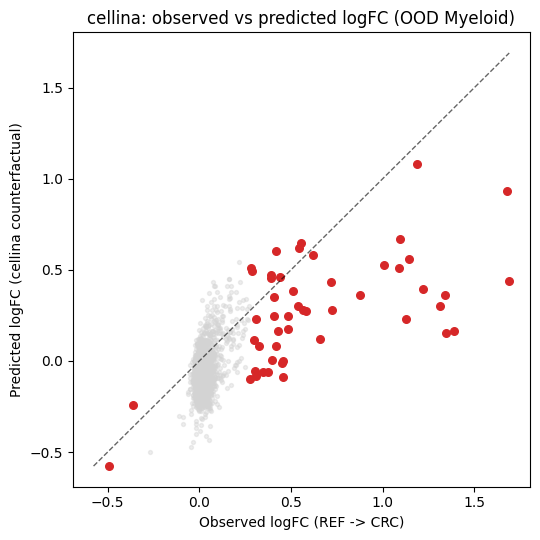

In [13]:
# Observed vs predicted logFC scatter (cellina) on the OOD held-out Myeloid, top DE genes.
import matplotlib.pyplot as plt
import numpy as np

ood = lambda a: a[(a.obs[LABELS_KEY].astype(str) == HOLDOUT_CT).values].copy()
obs_eff, pred_eff = get_perturbation_effects(
    ood(observed), ood(cellina_pred), pert_col=DOMAINS_KEY, control_label=CONTROL_LABEL,
    mode="logfc", predicted_logfc_baseline="predicted_control",
)
o = obs_eff.loc["CRC"].values
p = pred_eff.loc["CRC"].values
deg = np.argsort(-np.abs(o))[:50]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(o, p, s=8, color="lightgray", alpha=0.4)
ax.scatter(o[deg], p[deg], s=30, color="#d62728")
lims = [min(o.min(), p.min()), max(o.max(), p.max())]
ax.plot(lims, lims, "k--", lw=1, alpha=0.6)
ax.set_xlabel("Observed logFC (REF -> CRC)")
ax.set_ylabel("Predicted logFC (cellina counterfactual)")
ax.set_title("cellina: observed vs predicted logFC (OOD Myeloid)")
plt.tight_layout()
plt.show()